Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<ipython-input-2-6b7fe2df672b>:36: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))


Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241203_010634.jpg


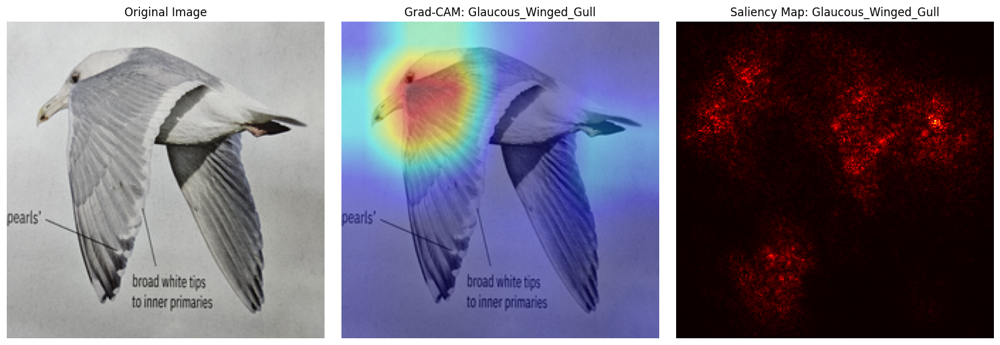

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241203_010647.jpg


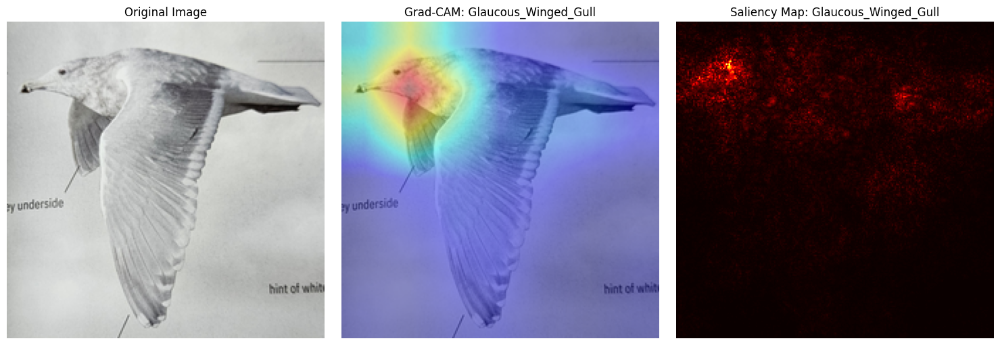

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_141028(1).jpg


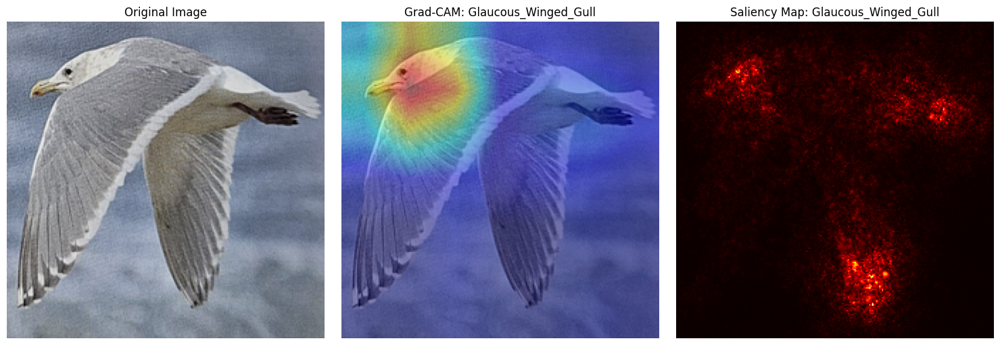

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_140935.jpg


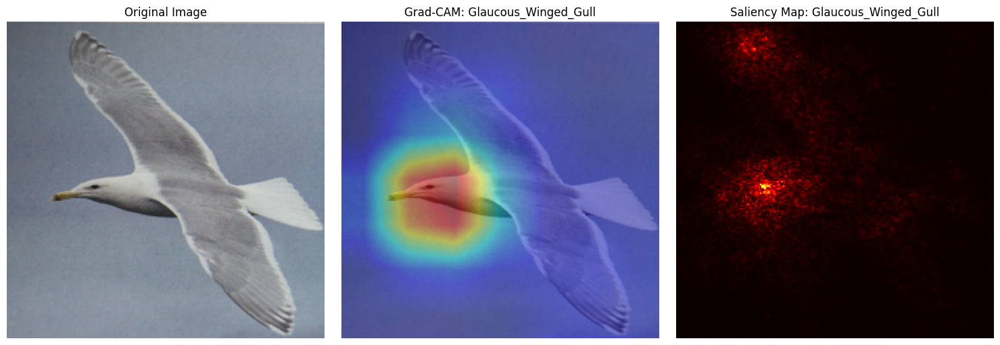

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_140922.jpg


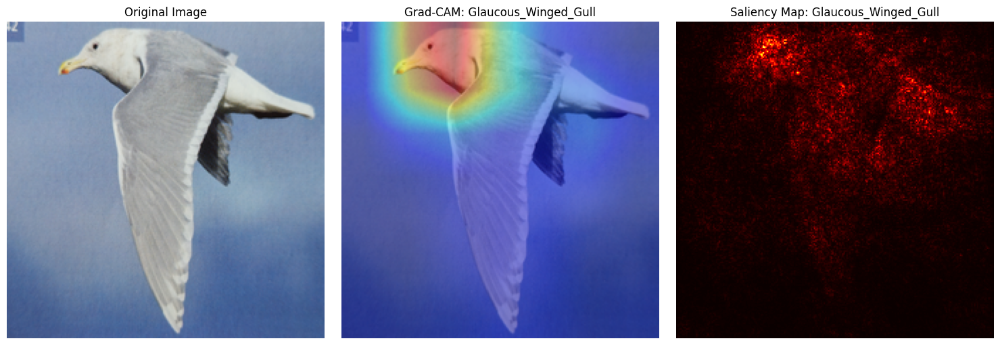

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_170956.jpg


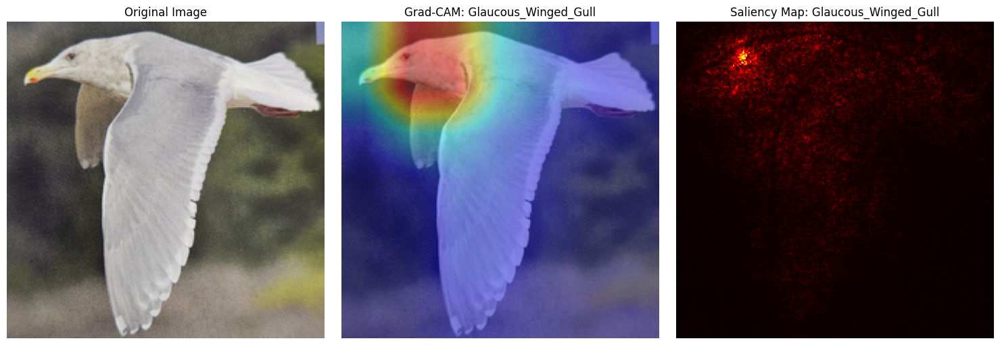

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_171004.jpg


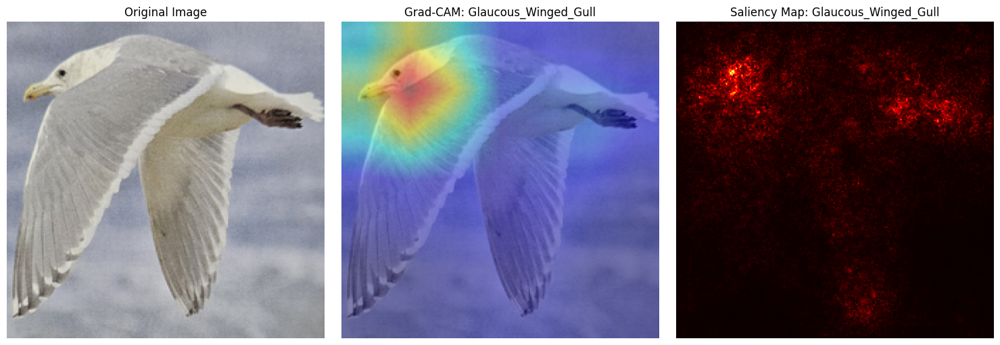

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Glaucous_Winged_Gull/20241204_171110.jpg


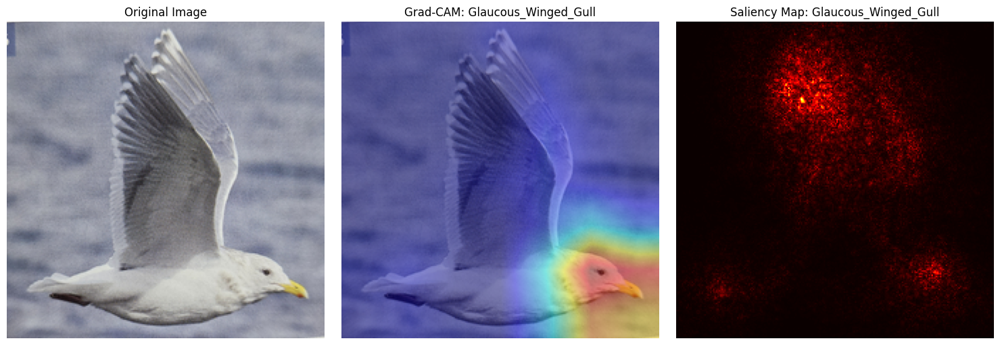

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_141619.jpg


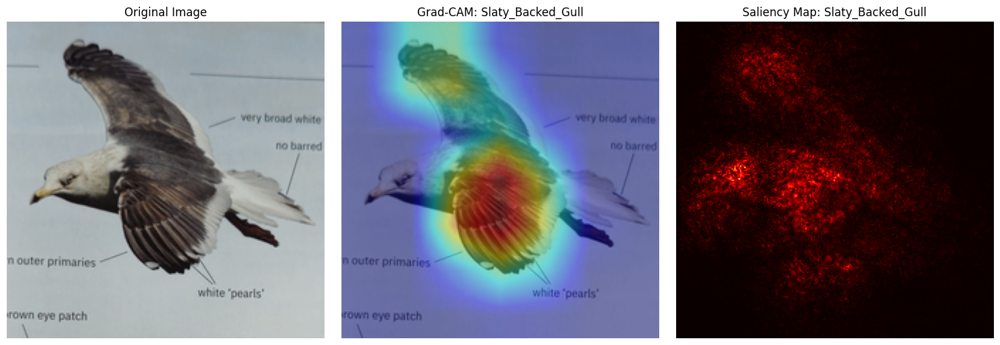

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_141608.jpg


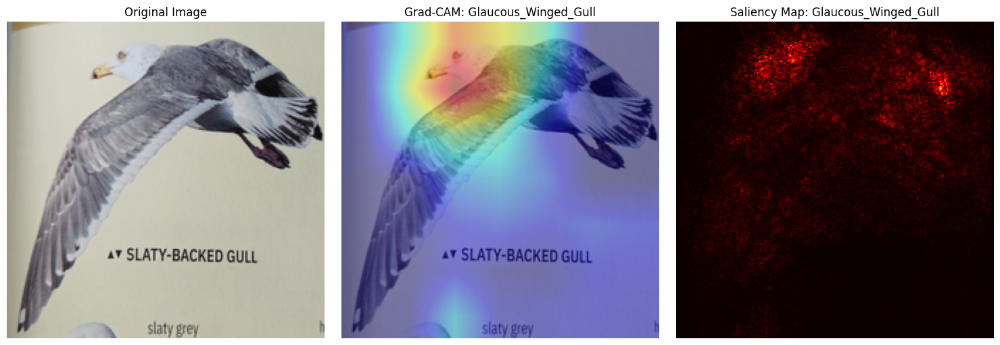

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_141506.jpg


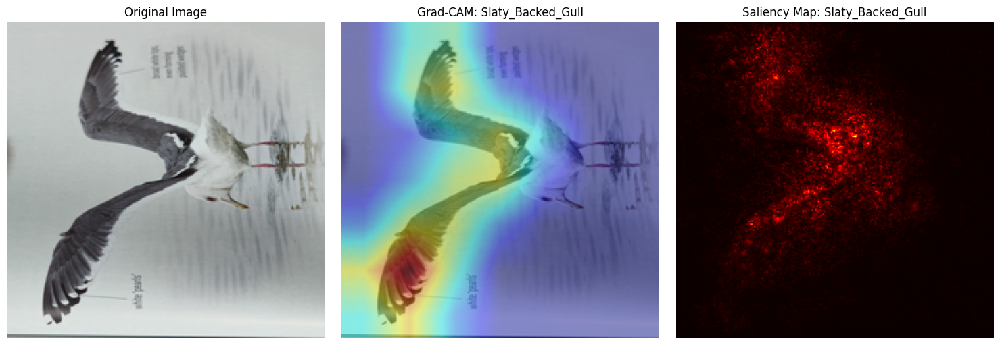

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_141028(1).jpg


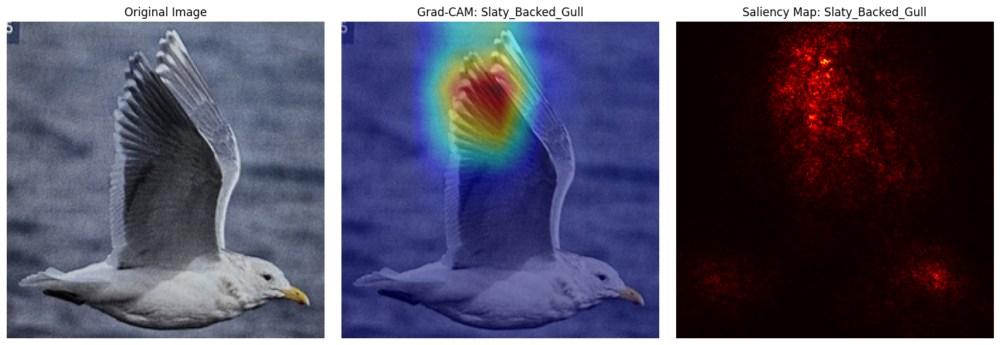

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_170328.jpg


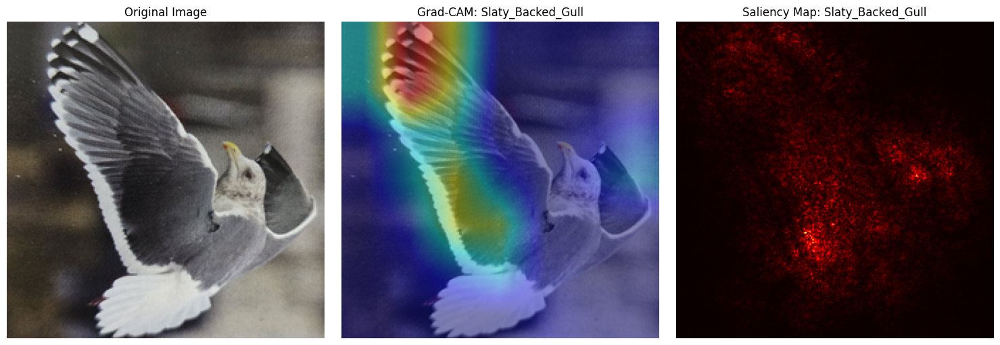

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_170332.jpg


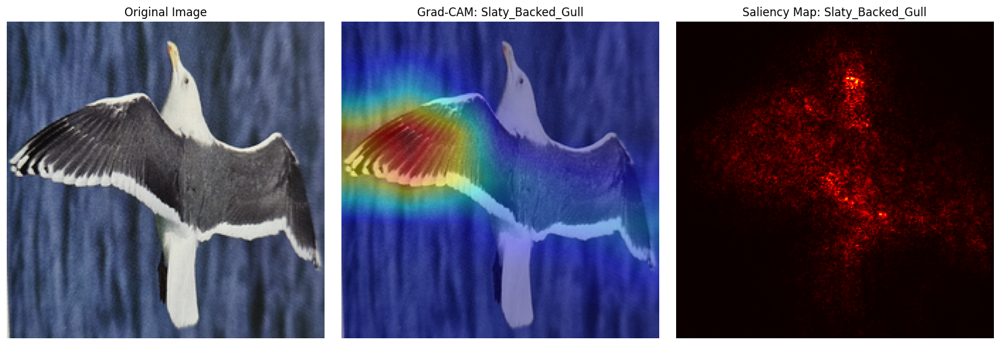

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_170314.jpg


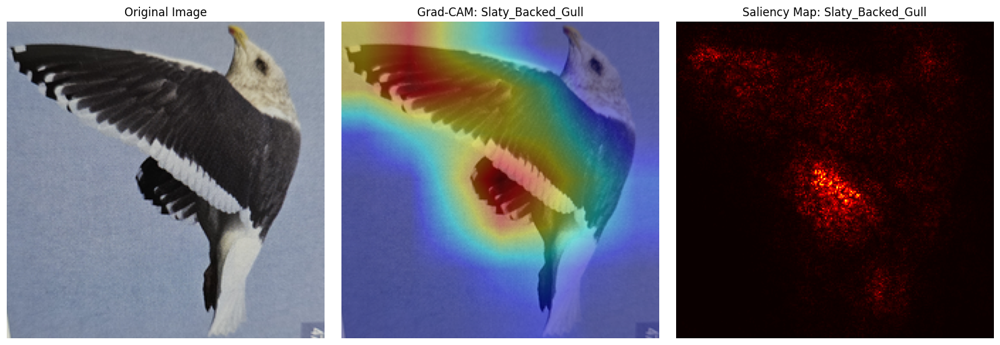

Processing: /content/drive/My Drive/FYP/BOOK_IMAGES_GULL/Slaty_Backed_Gull/20241204_170322.jpg


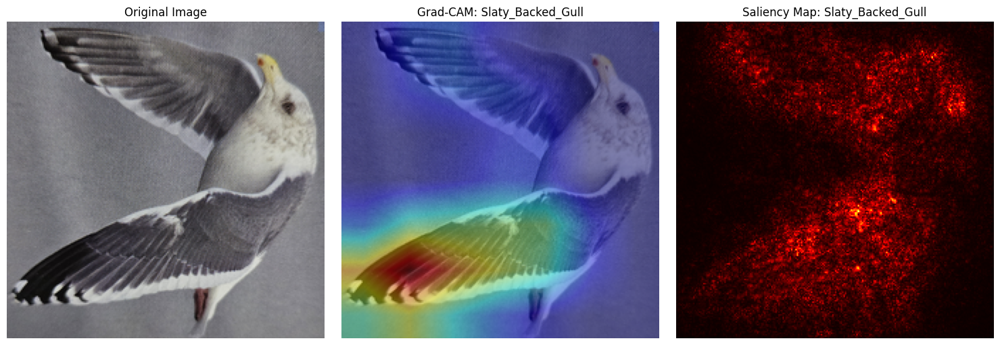

In [2]:
import os
import torch
import torch.nn as nn
from torchvision import transforms, models
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import cv2

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define model path and dataset path
checkpoint_path = '/content/drive/My Drive/FYP/VGGModel/HQ2ltst_20241218/final_model_vgg_20241218.pth'
test_folder_path = '/content/drive/My Drive/FYP/BOOK_IMAGES_GULL'  # Replace with your test folder path

# Load the trained VGG model
class VGG16Modified(nn.Module):
    def __init__(self):
        super(VGG16Modified, self).__init__()
        from torchvision.models import VGG16_Weights
        self.vgg = models.vgg16(weights=VGG16_Weights.IMAGENET1K_V1)
        # Replace the classifier with a custom binary classification layer
        num_ftrs = self.vgg.classifier[6].in_features
        self.vgg.classifier[6] = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(num_ftrs, 2)
        )

    def forward(self, x):
        return self.vgg(x)

# Initialize and load the model
model = VGG16Modified()
model.load_state_dict(torch.load(checkpoint_path, map_location=torch.device('cpu')))
model.eval()

# Define class names as per dataset
class_names = ['Glaucous_Winged_Gull', 'Slaty_Backed_Gull']  # Adjust based on your class order

# Define image transformation
transform = transforms.Compose([
    transforms.Resize((224, 224)),   # Resize to match VGG input size
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),  # ImageNet normalization
])

# Function to preprocess and load a single image
def preprocess_image(image_path):
    """Load an image and apply transformations."""
    image = Image.open(image_path).convert("RGB")
    image = transform(image)  # Apply transformations
    image = image.unsqueeze(0)  # Add batch dimension
    return image

# Grad-CAM implementation
def generate_gradcam(model, image_tensor, target_layer):
    model.eval()
    features = []
    grads = []

    # Define hooks to capture feature maps and gradients
    def save_features_hook(module, input, output):
        features.append(output)

    def save_grads_hook(module, grad_in, grad_out):
        grads.append(grad_out[0])

    # Register hooks to the target layer
    hook1 = target_layer.register_forward_hook(save_features_hook)
    hook2 = target_layer.register_backward_hook(save_grads_hook)

    # Forward pass
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()

    # Backward pass to get gradients
    model.zero_grad()
    class_loss = output[0, predicted_class_idx]
    class_loss.backward()

    # Process gradients and feature maps
    gradient = grads[0].cpu().data.numpy()[0]
    feature_map = features[0].cpu().data.numpy()[0]

    # Calculate Grad-CAM
    weights = np.mean(gradient, axis=(1, 2))  # Global average pooling of gradients
    cam = np.zeros(feature_map.shape[1:], dtype=np.float32)

    for i, w in enumerate(weights):
        cam += w * feature_map[i]

    cam = np.maximum(cam, 0)  # ReLU to remove negative values
    cam = cv2.resize(cam, (image_tensor.shape[3], image_tensor.shape[2]))  # Resize to match image dimensions
    cam -= np.min(cam)
    cam /= np.max(cam)  # Normalize between 0 and 1
    return cam, predicted_class_idx

# Saliency Map implementation
def generate_saliency_map(model, image_tensor):
    image_tensor.requires_grad_()
    output = model(image_tensor)
    predicted_class_idx = output.argmax().item()

    # Backward pass to calculate gradients
    model.zero_grad()
    output[0, predicted_class_idx].backward()

    # Calculate saliency
    saliency = image_tensor.grad.data.abs()
    saliency, _ = torch.max(saliency, dim=1)  # Take max across channels
    saliency = saliency.squeeze().cpu().numpy()

    # Normalize for visualization
    saliency = (saliency - saliency.min()) / (saliency.max() - saliency.min())
    return saliency, predicted_class_idx

# Function to visualize results
def visualize_results(image_path, gradcam, saliency, predicted_class):
    original_image = Image.open(image_path).resize((224, 224), Image.LANCZOS)
    original_image = np.array(original_image)

    # Grad-CAM heatmap overlay
    heatmap = cv2.applyColorMap(np.uint8(255 * gradcam), cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
    gradcam_image = np.clip(0.4 * heatmap + 0.6 * original_image, 0, 255).astype(np.uint8)

    # Plot images
    plt.figure(figsize=(15, 5))

    # Original Image
    plt.subplot(1, 3, 1)
    plt.title("Original Image")
    plt.imshow(original_image)
    plt.axis('off')

    # Grad-CAM
    plt.subplot(1, 3, 2)
    plt.title(f"Grad-CAM: {class_names[predicted_class]}")
    plt.imshow(gradcam_image)
    plt.axis('off')

    # Saliency Map
    plt.subplot(1, 3, 3)
    plt.title(f"Saliency Map: {class_names[predicted_class]}")
    plt.imshow(saliency, cmap='hot')
    plt.axis('off')

    plt.tight_layout()
    plt.show()

# Process all images in the test folder
def process_test_folder(test_folder_path):
    target_layer = model.vgg.features[-1]  # Target the last convolutional layer
    for root, _, files in os.walk(test_folder_path):
        for file in files:
            image_path = os.path.join(root, file)
            print(f"Processing: {image_path}")

            # Preprocess the image
            image_tensor = preprocess_image(image_path)

            # Generate Grad-CAM and Saliency Map
            gradcam, predicted_class_idx_cam = generate_gradcam(model, image_tensor, target_layer)
            saliency, predicted_class_idx_sal = generate_saliency_map(model, image_tensor)

            # Ensure predictions from both methods match
            assert predicted_class_idx_cam == predicted_class_idx_sal, "Predicted class mismatch!"

            # Visualize results
            visualize_results(image_path, gradcam, saliency, predicted_class_idx_cam)

# Run the combined implementation on all images in the test folder
process_test_folder(test_folder_path)
